# Étape 4 — Modèle Transformer : même tâche, avec l'auto-attention

Architecture (tableau, partie 4) :

```
Entrées x1..xn ──► Projection linéaire 1 → 16 ──┐
Indices 0..n-1 ──► Positional Embedding ────────┴─► (+) ──┬─────────────────────┐ (résiduel)
                                                          ▼                     │
                                     Multi-Head Self-Attention (2 têtes, d=16)  │
                                                          ▼                     ▼
                                                     Addition + Norm Layer ◄────┘
                                                          ▼ ─────────────────────┐ (résiduel)
                                          Feed Forward 16 → 32 → 16 (ReLU)       │
                                                          ▼                      ▼
                                                     Addition + Norm Layer ◄─────┘
                                                          ▼
                                   Garder la dernière représentation [:, -1, :]
                                                          ▼
                                                  Linear 16 → 1 → ŷ
```

Contrairement au RNN/LSTM, il n'y a **pas de mémoire récurrente** : toutes les positions sont traitées
**en parallèle** et l'attention met directement en relation chaque position avec les autres :

$$\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

In [1]:
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## 1. Données

In [2]:
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10

X = torch.stack([serie[i:i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
y = torch.stack([serie[i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
X, y = X.unsqueeze(-1), y.unsqueeze(-1)

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

## 2. Définir le modèle Transformer

In [3]:
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10, dimension=16):
        super().__init__()
        # Projection linéaire 1 -> 16
        self.projection = nn.Linear(1, dimension)
        # Positional embedding appris : un vecteur par position 0..9
        self.positions = nn.Embedding(longueur_max, dimension)
        # Bloc encodeur : MHSA (2 têtes) + Add&Norm + FFN 16->32->16 (ReLU) + Add&Norm
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            activation="relu",
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1, enable_nested_tensor=False)
        # Linear 16 -> 1
        self.sortie = nn.Linear(dimension, 1)

    def embed(self, x):
        indices = torch.arange(x.size(1), device=x.device)          # 0, 1, ..., n-1
        return self.projection(x) + self.positions(indices).unsqueeze(0)   # (B, 10, 16)

    def forward(self, x):
        z = self.embed(x)                     # (B, 10, 16)
        representations = self.encodeur(z)    # (B, 10, 16)
        derniere = representations[:, -1, :]  # (B, 16)  -> "garder la dernière représentation"
        return self.sortie(derniere)          # (B, 1)


modele = MiniTransformer()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

print(modele)
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

MiniTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (encodeur): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
        )
        (linear1): Linear(in_features=16, out_features=32, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=32, out_features=16, bias=True)
        (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
Nombre de paramètres : 2433


Vérification des dimensions à chaque étape :

In [4]:
with torch.no_grad():
    z = modele.embed(X_train[:4])
    r = modele.encodeur(z)
    print("Entrée               :", tuple(X_train[:4].shape))
    print("Projection + position:", tuple(z.shape))
    print("Encodeur             :", tuple(r.shape))
    print("Dernière position    :", tuple(r[:, -1, :].shape))
    print("Sortie               :", tuple(modele(X_train[:4]).shape))

Entrée               : (4, 10, 1)
Projection + position: (4, 10, 16)
Encodeur             : (4, 10, 16)
Dernière position    : (4, 16)
Sortie               : (4, 1)


## 3. Entraîner

In [5]:
historique = []
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    historique.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

Epoch  50 | Erreur : 0.001504


Epoch 100 | Erreur : 0.000110


Epoch 150 | Erreur : 0.000026


Epoch 200 | Erreur : 0.000012


Epoch 250 | Erreur : 0.000007


Epoch 300 | Erreur : 0.000004


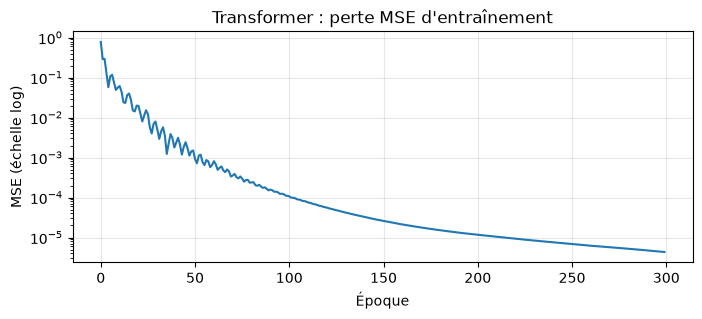

In [6]:
plt.figure(figsize=(8, 3))
plt.plot(historique)
plt.yscale("log")
plt.title("Transformer : perte MSE d'entraînement")
plt.xlabel("Époque")
plt.ylabel("MSE (échelle log)")
plt.grid(True, alpha=0.3)
plt.show()

## 4. Tester

In [7]:
modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)
    mae_test = (predictions - y_test).abs().mean()

print(f"MSE test : {erreur_test.item():.6f}")
print(f"MAE test : {mae_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

MSE test : 0.000006
MAE test : 0.002041
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


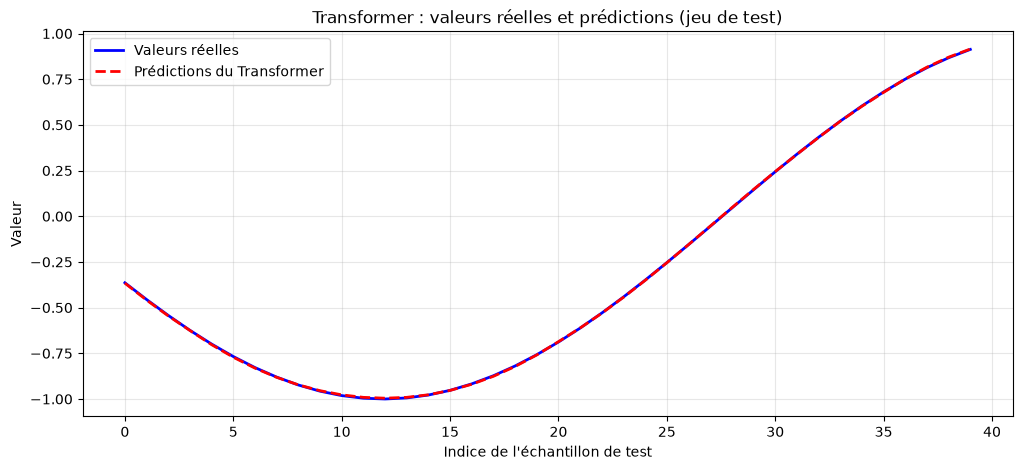

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.reshape(-1), label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(predictions.reshape(-1), label="Prédictions du Transformer", color="red", linestyle="--", linewidth=2)
plt.title("Transformer : valeurs réelles et prédictions (jeu de test)")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Visualiser les poids d'attention

On recalcule l'auto-attention de la couche pour une séquence de test : la ligne $i$ indique
**à quelles positions** la position $i$ fait attention (moyenne des 2 têtes).
La dernière ligne est la plus importante : c'est la représentation utilisée pour la prédiction.

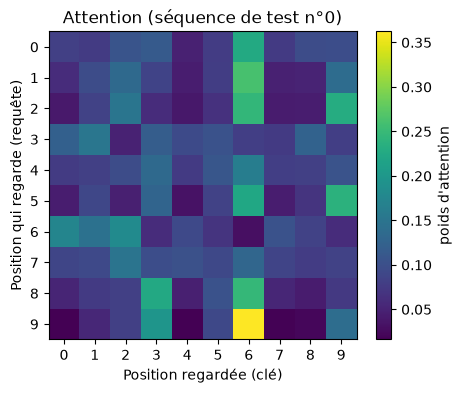

In [9]:
couche = modele.encodeur.layers[0]
with torch.no_grad():
    z = modele.embed(X_test[:1])
    _, poids = couche.self_attn(z, z, z, need_weights=True, average_attn_weights=True)

plt.figure(figsize=(5, 4))
plt.imshow(poids[0], cmap="viridis")
plt.colorbar(label="poids d'attention")
plt.title("Attention (séquence de test n°0)")
plt.xlabel("Position regardée (clé)")
plt.ylabel("Position qui regarde (requête)")
plt.xticks(range(10))
plt.yticks(range(10))
plt.show()

## 6. Comparaison RNN / LSTM / Transformer

On ré-entraîne les trois modèles dans les mêmes conditions (même données, 300 époques, Adam lr=0.01, même graine).

In [10]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        return self.sortie(self.rnn(x)[0][:, -1, :])


class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        return self.sortie(self.lstm(x)[0][:, -1, :])


def entrainer_et_tester(classe):
    torch.manual_seed(42)
    m = classe()
    opt = torch.optim.Adam(m.parameters(), lr=0.01)
    debut = time.time()
    m.train()
    for _ in range(300):
        perte = critere(m(X_train), y_train)
        opt.zero_grad()
        perte.backward()
        opt.step()
    duree = time.time() - debut
    m.eval()
    with torch.no_grad():
        p = m(X_test)
    return {
        "params": sum(q.numel() for q in m.parameters()),
        "mse": critere(p, y_test).item(),
        "mae": (p - y_test).abs().mean().item(),
        "temps": duree,
        "pred": p.reshape(-1),
    }


resultats = {nom: entrainer_et_tester(c) for nom, c in
             [("RNN", SimpleRNN), ("LSTM", SimpleLSTM), ("Transformer", MiniTransformer)]}

print(f"{'Modèle':<12} {'Paramètres':>10} {'MSE test':>12} {'MAE test':>10} {'Temps (s)':>10}")
for nom, r in resultats.items():
    print(f"{nom:<12} {r['params']:>10} {r['mse']:>12.6f} {r['mae']:>10.4f} {r['temps']:>10.2f}")

Modèle       Paramètres     MSE test   MAE test  Temps (s)
RNN                 321     0.000028     0.0046       3.45
LSTM               1233     0.000003     0.0014       4.92
Transformer        2433     0.000006     0.0020       3.20


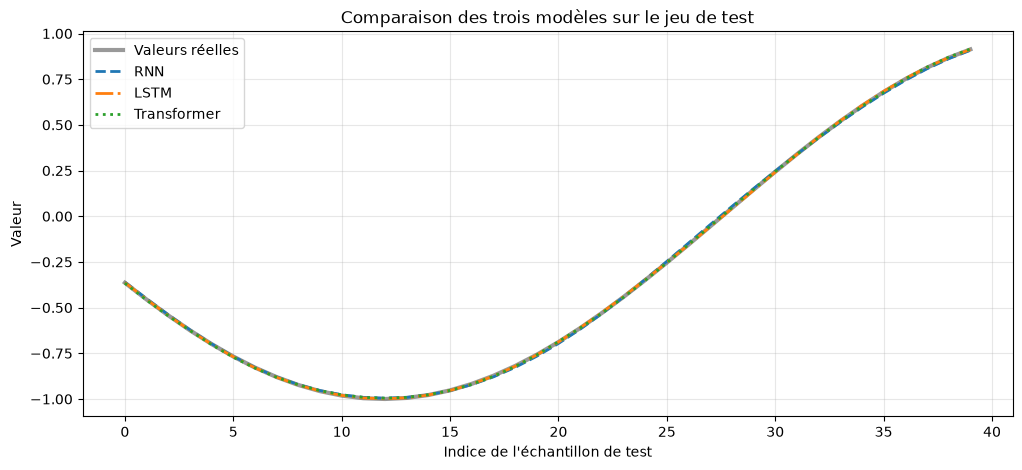

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.reshape(-1), label="Valeurs réelles", color="black", linewidth=3, alpha=0.4)
for nom, style in [("RNN", "--"), ("LSTM", "-."), ("Transformer", ":")]:
    plt.plot(resultats[nom]["pred"], linestyle=style, linewidth=2, label=nom)
plt.title("Comparaison des trois modèles sur le jeu de test")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Conclusion

- Les trois modèles prédisent correctement la sinusoïde ; la tâche est simple et courte (10 pas).
- Le Transformer remplace la récurrence par l'**auto-attention** : chaque position accède directement à toutes les autres,
  et les calculs sur la longueur se font en parallèle. Il a besoin d'un **encodage de position** car l'attention seule ignore l'ordre.
- C'est cette architecture qui est à la base de **GPT** (décodeur, attention causale) et **BERT** (encodeur, attention bidirectionnelle).

➡️ Étape suivante : `05_gpt.ipynb`